                       Text  Sentiment
0       I love this product          1
1           This is amazing          1
2           I am very happy          1
3   The movie was excellent          1
4            I enjoyed this          1
5          Great experience          1
6       I hate this product          0
7          This is terrible          0
8             I am very sad          0
9      The movie was boring          0
10          I disliked this          0
11           Bad experience          0
Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 175ms/step - accuracy: 0.4286 - loss: 0.7037 - val_accuracy: 0.5000 - val_loss: 0.6708
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.4286 - loss: 0.6919 - val_accuracy: 0.5000 - val_loss: 0.6790
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7143 - loss: 0.6825 - val_accuracy: 0.5000 - val_loss: 0.6861
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7143 - loss: 0.6697 - val_accuracy: 0.5000 - val_loss:

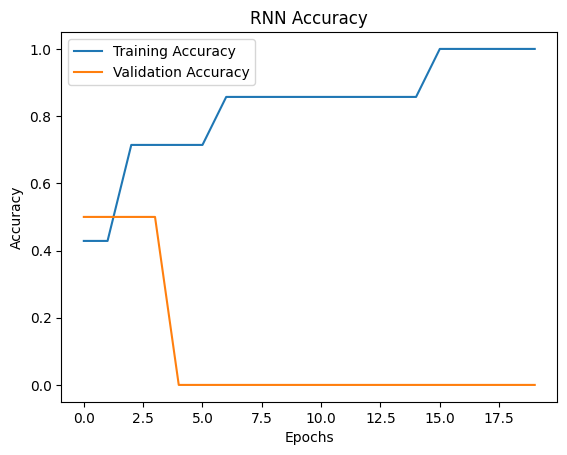

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

# Create dataset
data = {
    'Text': [
        'I love this product',
        'This is amazing',
        'I am very happy',
        'The movie was excellent',
        'I enjoyed this',
        'Great experience',
        'I hate this product',
        'This is terrible',
        'I am very sad',
        'The movie was boring',
        'I disliked this',
        'Bad experience'
    ],
    'Sentiment': [1,1,1,1,1,1,0,0,0,0,0,0]
}

df = pd.DataFrame(data)
print(df)

# Split data
X = df['Text']
y = df['Sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Tokenization
tokenizer = Tokenizer(num_words=100, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

# Padding
X_train = pad_sequences(X_train, maxlen=5, padding='post')
X_test = pad_sequences(X_test, maxlen=5, padding='post')

# Build RNN model
model = Sequential([
    Embedding(input_dim=100, output_dim=16),
    SimpleRNN(16),
    Dense(1, activation='sigmoid')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=2,
    validation_split=0.2
)

# Prediction
y_pred = (model.predict(X_test) > 0.5).astype(int)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('RNN Accuracy')
plt.legend()
plt.show()
